# 05 · Treinamento inicial

Treina as três arquiteturas com a configuração inicial do notebook 04, sob o mesmo protocolo: mesmos dados e partição, mesma perda (`BCEWithLogitsLoss`) e otimizador (Adam), mesmo *early stopping* sobre a perda de validação, mesmo limite de épocas, mesmo tamanho de *batch* e mesma semente.

Este treinamento foi feito **sem *gradient clipping***. Nele, a BiLSTM ficou instável e não passou de cerca de 0,68 de AUC-ROC de validação (Apêndice B do TCC, Seção B.1), o que levou à inclusão do *clipping* na busca de hiperparâmetros (notebook 05b). Os modelos finais saem dos notebooks 05b e 05c.

Precisa de GPU (T4). Cada modelo treinado é salvo no Drive, e os já treinados são pulados em uma nova execução.

## 1. Configuração e sementes

In [ ]:
import os, json, time, random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR   = '/content/drive/MyDrive/TCC-Exoplanetas'
MODELS_DIR = f'{DATA_DIR}/modelos'
os.makedirs(MODELS_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__, '| device:', device)
if device == 'cpu':
    print('*** ATENCAO: sem GPU. Ative Runtime -> T4 GPU antes de treinar. ***')

Mounted at /content/drive
PyTorch: 2.11.0+cu130 | device: cuda


In [ ]:
SEED = 42

def fixar_sementes(seed=SEED):
    """Fixa todas as fontes de aleatoriedade (reprodutibilidade)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# --- Hiperparametros IDENTICOS para as tres arquiteturas (controle experimental) ---
BATCH_SIZE  = 64
MAX_EPOCAS  = 50
LR          = 1e-3
PACIENCIA   = 8      # epocas sem melhora na perda de validacao
print('Protocolo: batch', BATCH_SIZE, '| max epocas', MAX_EPOCAS, '| lr', LR, '| paciencia', PACIENCIA)

Protocolo: batch 64 | max epocas 50 | lr 0.001 | paciencia 8


## 2. Dados

In [ ]:
d = np.load(f'{DATA_DIR}/dataset.npz')

class VisoesDataset(Dataset):
    """Cada item: (visao_global (1,2001), visao_local (1,201), rotulo)."""
    def __init__(self, Xg, Xl, y):
        self.Xg = torch.from_numpy(Xg).float().unsqueeze(1)
        self.Xl = torch.from_numpy(Xl).float().unsqueeze(1)
        self.y  = torch.from_numpy(y).float()

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.Xg[i], self.Xl[i], self.y[i]

ds_train = VisoesDataset(d['Xg_train'], d['Xl_train'], d['y_train'])
ds_val   = VisoesDataset(d['Xg_val'],   d['Xl_val'],   d['y_val'])
ds_test  = VisoesDataset(d['Xg_test'],  d['Xl_test'],  d['y_test'])

print(f'treino {len(ds_train)} | val {len(ds_val)} | teste {len(ds_test)}')
print(f'positivos — treino {d["y_train"].mean():.3f} | val {d["y_val"].mean():.3f} | teste {d["y_test"].mean():.3f}')

treino 6312 | val 683 | teste 670
positivos — treino 0.500 | val 0.425 | teste 0.379


## 3. Arquiteturas

As mesmas do notebook 04.

In [ ]:
class DoisRamos(nn.Module):
    def __init__(self, fabrica_ramo, p_dropout=0.3):
        super().__init__()
        self.ramo_global = fabrica_ramo()
        self.ramo_local  = fabrica_ramo()
        d_ = self.ramo_global.out_dim
        self.cabeca = nn.Sequential(
            nn.Linear(2 * d_, 64), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(64, 1),
        )

    def forward(self, g, l):
        z = torch.cat([self.ramo_global(g), self.ramo_local(l)], dim=1)
        return self.cabeca(z).squeeze(-1)


class RamoCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(),
            nn.AdaptiveMaxPool1d(1),
        )
        self.out_dim = 64

    def forward(self, x):
        return self.net(x).squeeze(-1)


class RamoBiLSTM(nn.Module):
    def __init__(self, hidden=64, camadas=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=camadas, batch_first=True,
                            bidirectional=True, dropout=0.1)
        self.out_dim = 2 * hidden

    def forward(self, x):
        saida, _ = self.lstm(x.transpose(1, 2))
        return saida.mean(dim=1)


def codificacao_posicional(comprimento, dim, device):
    pos = torch.arange(comprimento, device=device).unsqueeze(1).float()
    i   = torch.arange(dim, device=device).unsqueeze(0).float()
    ang = pos / torch.pow(torch.tensor(10000.0, device=device), (2 * (i // 2)) / dim)
    pe = torch.zeros(comprimento, dim, device=device)
    pe[:, 0::2] = torch.sin(ang[:, 0::2])
    pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe.unsqueeze(0)


class RamoTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, camadas=2, stride=8):
        super().__init__()
        self.embed = nn.Conv1d(1, d_model, kernel_size=2 * stride + 1,
                               stride=stride, padding=stride)
        camada = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=128,
                                            dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas)
        self.out_dim = d_model

    def forward(self, x):
        z = self.embed(x).transpose(1, 2)
        z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
        return self.encoder(z).mean(dim=1)


ARQUITETURAS = {
    'cnn1d':       ('CNN 1D',      RamoCNN),
    'bilstm':      ('BiLSTM',      RamoBiLSTM),
    'transformer': ('Transformer', RamoTransformer),
}

## 4. Laço de treinamento

O mesmo para as três arquiteturas. A cada época, registra a perda de treino, a perda de validação e a AUC-ROC de validação, aplica o *early stopping* e guarda os pesos da época com a menor perda de validação. O tempo de treinamento também é registrado.

In [ ]:
@torch.no_grad()
def avaliar(modelo, loader, criterio):
    modelo.eval()
    perdas, probs, alvos = [], [], []
    for g, l, y in loader:
        g, l, y = g.to(device), l.to(device), y.to(device)
        logits = modelo(g, l)
        perdas.append(criterio(logits, y).item() * len(y))
        probs.append(torch.sigmoid(logits).cpu().numpy())
        alvos.append(y.cpu().numpy())
    probs = np.concatenate(probs); alvos = np.concatenate(alvos)
    return sum(perdas) / len(alvos), roc_auc_score(alvos, probs)


def treinar(slug):
    nome, fabrica = ARQUITETURAS[slug]
    ckpt = f'{MODELS_DIR}/{slug}.pt'
    hist_path = f'{MODELS_DIR}/{slug}_historico.json'
    if os.path.exists(ckpt):
        print(f'[pulado] {nome} ja treinado ({ckpt})')
        return

    fixar_sementes()          # mesma inicializacao para todas
    g_loader = torch.Generator(); g_loader.manual_seed(SEED)
    dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True, generator=g_loader)
    dl_val   = DataLoader(ds_val,   batch_size=BATCH_SIZE)

    modelo   = DoisRamos(fabrica).to(device)
    criterio = nn.BCEWithLogitsLoss()
    otim     = torch.optim.Adam(modelo.parameters(), lr=LR)

    n_par = sum(p.numel() for p in modelo.parameters())
    print(f'\n=== {nome} | {n_par:,} parametros ===')

    melhor, paciencia, melhor_estado = float('inf'), 0, None
    hist = {'perda_treino': [], 'perda_val': [], 'auc_val': []}
    t0 = time.time()

    for epoca in range(1, MAX_EPOCAS + 1):
        modelo.train()
        soma = 0.0
        for g, l, y in dl_train:
            g, l, y = g.to(device), l.to(device), y.to(device)
            otim.zero_grad()
            perda = criterio(modelo(g, l), y)
            perda.backward()
            otim.step()
            soma += perda.item() * len(y)
        perda_treino = soma / len(ds_train)
        perda_val, auc_val = avaliar(modelo, dl_val, criterio)

        hist['perda_treino'].append(perda_treino)
        hist['perda_val'].append(perda_val)
        hist['auc_val'].append(auc_val)
        print(f'  ep {epoca:02d}  treino {perda_treino:.4f}  val {perda_val:.4f}  AUC {auc_val:.4f}')

        if perda_val < melhor - 1e-5:
            melhor, paciencia = perda_val, 0
            melhor_estado = {k: v.cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            paciencia += 1
            if paciencia >= PACIENCIA:
                print(f'  early stopping na epoca {epoca}')
                break

    dur = time.time() - t0
    torch.save(melhor_estado, ckpt)
    hist.update({'arquitetura': nome, 'parametros': n_par,
                 'melhor_perda_val': melhor, 'tempo_treino_s': dur,
                 'epocas_treinadas': len(hist['perda_treino'])})
    with open(hist_path, 'w') as f:
        json.dump(hist, f, indent=2)
    print(f'  salvo: {ckpt}  |  tempo {dur/60:.1f} min  |  melhor val {melhor:.4f}')

## 5. Treinamento

As três arquiteturas são treinadas em sequência. A BiLSTM é a mais lenta por época, porque percorre os 2.001 passos da Visão Global de forma sequencial.

In [ ]:
for slug in ARQUITETURAS:
    treinar(slug)


=== CNN 1D | 34,305 parametros ===
  ep 01  treino 0.6633  val 0.5925  AUC 0.8025
  ep 02  treino 0.4049  val 0.3743  AUC 0.9338
  ep 03  treino 0.3165  val 0.3241  AUC 0.9442
  ep 04  treino 0.2923  val 0.3060  AUC 0.9418
  ep 05  treino 0.2750  val 0.3072  AUC 0.9442
  ep 06  treino 0.2801  val 0.3055  AUC 0.9430
  ep 07  treino 0.2618  val 0.3621  AUC 0.9453
  ep 08  treino 0.2674  val 0.3010  AUC 0.9466
  ep 09  treino 0.2535  val 0.2943  AUC 0.9485
  ep 10  treino 0.2466  val 0.3022  AUC 0.9452
  ep 11  treino 0.2364  val 0.3219  AUC 0.9485
  ep 12  treino 0.2271  val 0.2812  AUC 0.9525
  ep 13  treino 0.2217  val 0.2955  AUC 0.9526
  ep 14  treino 0.2216  val 0.3411  AUC 0.9474
  ep 15  treino 0.2239  val 0.3509  AUC 0.9509
  ep 16  treino 0.2217  val 0.2783  AUC 0.9551
  ep 17  treino 0.2091  val 0.2996  AUC 0.9517
  ep 18  treino 0.2004  val 0.2923  AUC 0.9527
  ep 19  treino 0.2108  val 0.2970  AUC 0.9537
  ep 20  treino 0.1970  val 0.3089  AUC 0.9519
  ep 21  treino 0.1979  

## 6. Curvas de validação

Base da Figura 10 do TCC.

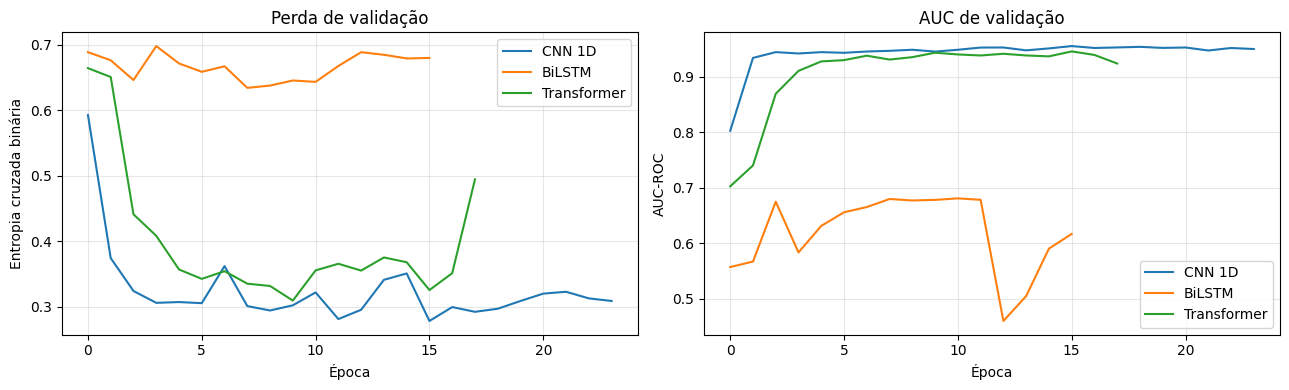

CNN 1D       params    34,305  epocas 24  melhor val 0.2783  tempo 0.3 min
BiLSTM       params   283,777  epocas 16  melhor val 0.6340  tempo 1.8 min
Transformer  params   144,513  epocas 18  melhor val 0.3094  tempo 0.8 min


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for slug, (nome, _) in ARQUITETURAS.items():
    p = f'{MODELS_DIR}/{slug}_historico.json'
    if not os.path.exists(p):
        continue
    h = json.load(open(p))
    ax[0].plot(h['perda_val'], label=nome)
    ax[1].plot(h['auc_val'], label=nome)

ax[0].set_title('Perda de validação'); ax[0].set_ylabel('Entropia cruzada binária')
ax[1].set_title('AUC de validação');   ax[1].set_ylabel('AUC-ROC')
for a in ax: a.set_xlabel('Época'); a.legend(); a.grid(alpha=0.3)
FIG_DIR = f'{DATA_DIR}/figuras'; os.makedirs(FIG_DIR, exist_ok=True)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/curvas_treino_baseline.png', dpi=300); plt.show()

for slug, (nome, _) in ARQUITETURAS.items():
    p = f'{MODELS_DIR}/{slug}_historico.json'
    if os.path.exists(p):
        h = json.load(open(p))
        print(f"{nome:12s} params {h['parametros']:>9,}  epocas {h['epocas_treinadas']:>2}  "
              f"melhor val {h['melhor_perda_val']:.4f}  tempo {h['tempo_treino_s']/60:.1f} min")

## Próximo passo

O notebook 05b repete o treinamento com *gradient clipping* e faz a busca de hiperparâmetros.